In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [10]:
n = 100
study_hours = np.linspace (0, 30, n)

base_score = 25 + 6 * study_hours - 0.15 * study_hours**2
noise = np.random.normal (0, 4, n)
test_scores = base_score + noise

# can you visualize this now?

In [19]:
study_hours

array([ 0.        ,  0.3030303 ,  0.60606061,  0.90909091,  1.21212121,
        1.51515152,  1.81818182,  2.12121212,  2.42424242,  2.72727273,
        3.03030303,  3.33333333,  3.63636364,  3.93939394,  4.24242424,
        4.54545455,  4.84848485,  5.15151515,  5.45454545,  5.75757576,
        6.06060606,  6.36363636,  6.66666667,  6.96969697,  7.27272727,
        7.57575758,  7.87878788,  8.18181818,  8.48484848,  8.78787879,
        9.09090909,  9.39393939,  9.6969697 , 10.        , 10.3030303 ,
       10.60606061, 10.90909091, 11.21212121, 11.51515152, 11.81818182,
       12.12121212, 12.42424242, 12.72727273, 13.03030303, 13.33333333,
       13.63636364, 13.93939394, 14.24242424, 14.54545455, 14.84848485,
       15.15151515, 15.45454545, 15.75757576, 16.06060606, 16.36363636,
       16.66666667, 16.96969697, 17.27272727, 17.57575758, 17.87878788,
       18.18181818, 18.48484848, 18.78787879, 19.09090909, 19.39393939,
       19.6969697 , 20.        , 20.3030303 , 20.60606061, 20.90

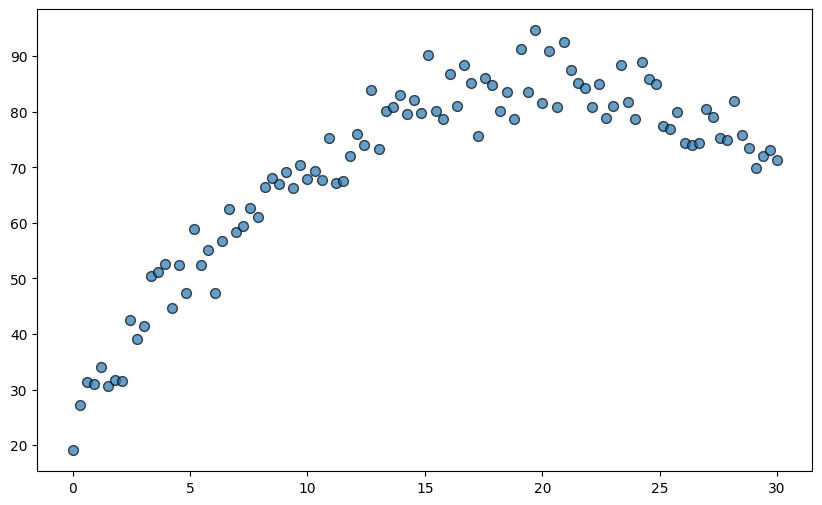

In [13]:
plt.figure(figsize=(10,6))
plt.scatter (study_hours, test_scores, s=50, alpha=0.7, edgecolors='black', linewidth=1)

In [14]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression


In [18]:
X_sample = np.array ([[1], [2], [3], [4]])

poly = PolynomialFeatures (degree=3, include_bias=False)
X_poly = poly.fit_transform (X_sample)
X_poly

array([[ 1.,  1.,  1.],
       [ 2.,  4.,  8.],
       [ 3.,  9., 27.],
       [ 4., 16., 64.]])

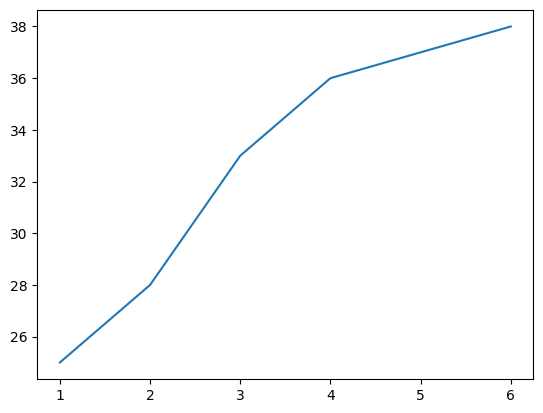

In [24]:
hours = np.array([1, 2, 3, 4, 5, 6])
scores = np.array([25, 28, 33, 36, 37, 38])

plt.plot (hours, scores)

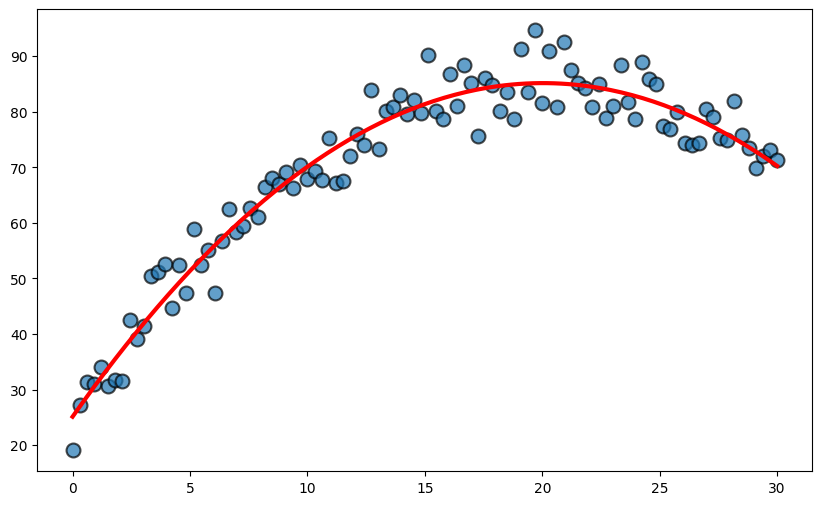

In [30]:
X_train = study_hours.reshape(-1, 1) # independent variable
y_train = test_scores # dependant variable


poly = PolynomialFeatures (degree=2, include_bias=False)
X_poly = poly.fit_transform (X_train)

model = LinearRegression ()
model.fit (X_poly, y_train)

# x for plotting, not calcluations
X_plot = np.linspace (study_hours.min(), study_hours.max(), 200).reshape (-1, 1)
X_plot_ploy = poly.transform (X_plot)
y_pred = model.predict (X_plot_ploy)


plt.figure (figsize=(10,6))
plt.scatter (X_train,
             y_train,
             s=100,
             alpha=0.7,
             edgecolors='black',
             linewidth=1.5)

plt.plot(X_plot, y_pred, 'r-', linewidth=3)

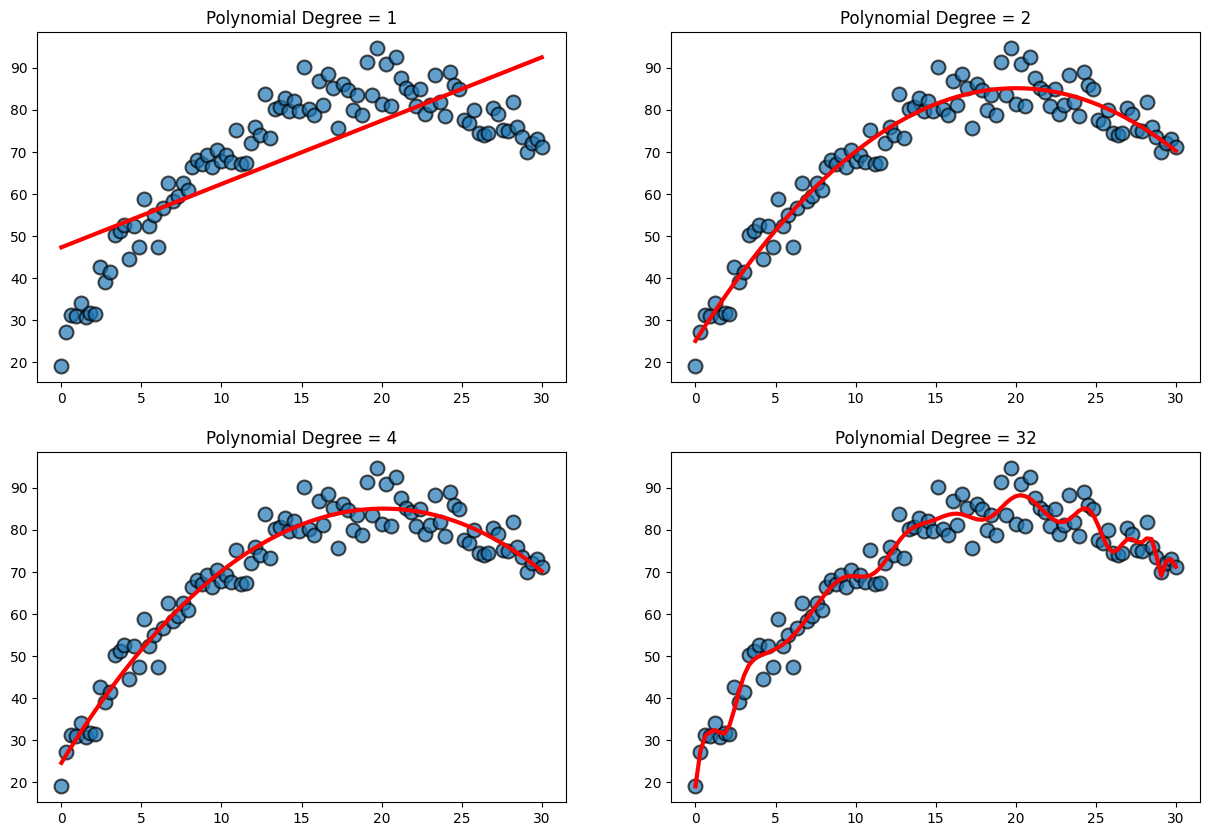

In [37]:
X = study_hours.reshape(-1, 1)
y = test_scores.reshape(-1, 1)

X_mean = np.mean(X)
X_std = np.std(X)
X_normalized = (X - X_mean) / X_std

degrees = [1, 2, 4, 32]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

for idx, degree in enumerate (degrees):
    poly = PolynomialFeatures (degree=degree, include_bias=False)
    X_poly = poly.fit_transform (X_normalized)

    model = LinearRegression ()
    model.fit (X_poly, y)
    y_pred = model.predict(X_poly)
    axes[idx].scatter(X,
                      y,
                      s=100,
                      alpha=0.7,
                      edgecolors='black',
                      linewidth=1.5)
    axes[idx].set_title(f'Polynomial Degree = {degree}')

    axes[idx].plot(X, y_pred, 'r-', linewidth=3)

In [41]:
# study_hours
# test_scores
# take 80% for training
# keep 20% for validating

In [42]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

X_train, X_temp, y_train, y_temp = train_test_split (study_hours.reshape(-1,1),
                                                     test_scores.reshape(-1,1),
                                                     test_size=0.4,
                                                     random_state=42)

X_val, X_test, y_val, y_test = train_test_split (X_temp,
                                                 y_temp,
                                                 test_size=0.5,
                                                 random_state=42)

X_mean = np.mean (X_train)
X_std = np.std (X_train)
X_train_norm = (X_train - X_mean) / X_std
X_val_norm = (X_val - X_mean) / X_std
X_test_norm = (X_test - X_mean) / X_std

degrees = [1, 2, 3, 4, 5, 6, 8, 12, 16, 32]
train_errors = [] # how badly we did during training
val_errors = [] # how badly we did during validation

for degree in degrees:
    poly = PolynomialFeatures (degree=degree, include_bias=False)
    X_train_poly = poly.fit_transform (X_train_norm)

    model = LinearRegression ()
    model.fit (X_train_poly, y_train)

    # predication for training and prediction for validtion datasets
    y_train_pred = model.predict(X_train_poly) # first prediction for training

    X_val_poly = poly.transform (X_val_norm)
    y_val_pred = model.predict(X_val_poly) # second prediction for validation

    train_mse = mean_squared_error (y_train, y_train_pred)
    val_mse = mean_squared_error (y_val, y_val_pred)

    train_errors.append (train_mse)
    val_errors.append (val_mse)

    print (f'Degree: {degree}, Train MSE: {train_mse:.2f}, Validation MSE: {val_mse:.2f}')


best_degree = degrees[np.argmin(val_errors)]
#

Degree: 1, Train MSE: 117.88, Validation MSE: 107.16
Degree: 2, Train MSE: 13.94, Validation MSE: 17.16
Degree: 3, Train MSE: 13.92, Validation MSE: 17.23
Degree: 4, Train MSE: 13.87, Validation MSE: 17.38
Degree: 5, Train MSE: 13.73, Validation MSE: 16.92
Degree: 6, Train MSE: 13.71, Validation MSE: 17.28
Degree: 8, Train MSE: 13.57, Validation MSE: 17.17
Degree: 12, Train MSE: 13.36, Validation MSE: 15.56
Degree: 16, Train MSE: 11.43, Validation MSE: 13.86
Degree: 32, Train MSE: 7.52, Validation MSE: 59.91
